# Análise Exploratória — Wine Quality

Este notebook explora o dataset **já limpo** (`data/processed/winequality_clean.csv`,
gerado por `data/processing.py`). Os problemas do dataset bruto e as correções
aplicadas estão documentados em `raw_data_investigation.ipynb` e no README.

O objetivo é entender as variáveis e a relação delas com a `quality` (target)
para embasar as decisões de pré-processamento e modelagem das partes de
regressão e classificação.

## 1. Setup

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv("../data/processed/winequality_clean.csv")

## 2. Visão geral dos dados

Dimensões, tipos das colunas, estatísticas descritivas e valores vazios que
restaram após a limpeza.

In [6]:
print(f"{df.shape[0]} linhas x {df.shape[1]} colunas")
print(df["type"].value_counts())
print()

df.info()

5317 linhas x 13 colunas
type
white    3958
red      1359
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 5317 entries, 0 to 5316
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5315 non-null   float64
 1   volatile acidity      5317 non-null   float64
 2   citric acid           5315 non-null   float64
 3   residual sugar        5316 non-null   float64
 4   chlorides             5316 non-null   float64
 5   free sulfur dioxide   5315 non-null   float64
 6   total sulfur dioxide  5317 non-null   float64
 7   density               5315 non-null   float64
 8   pH                    5315 non-null   float64
 9   sulphates             5222 non-null   float64
 10  alcohol               5317 non-null   float64
 11  type                  5317 non-null   str    
 12  quality               5317 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 54

In [7]:
# .T transpõe a tabela: uma linha por variável fica mais fácil de ler
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5315.0,7.216,1.320,3.800,6.400,7.000,7.700,15.900
volatile acidity,5317.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,5315.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,5316.0,5.049,4.501,0.600,1.800,2.700,7.500,65.800
chlorides,5316.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,5315.0,30.031,17.808,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,5317.0,114.085,56.781,6.000,74.000,116.000,153.000,440.000
density,5315.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5315.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5222.0,0.534,0.149,0.220,0.430,0.510,0.600,2.000


In [8]:
# Mostra só as colunas que ainda têm vazios; serão imputados após o split treino/teste
vazios = df.isna().sum()
vazios[vazios > 0].sort_values(ascending=False)

sulphates              95
fixed acidity           2
free sulfur dioxide     2
citric acid             2
density                 2
pH                      2
chlorides               1
residual sugar          1
dtype: int64

### Observações

_TODO_

## 3. Variável alvo (`quality`)

Distribuição das notas, separada por tipo de vinho.

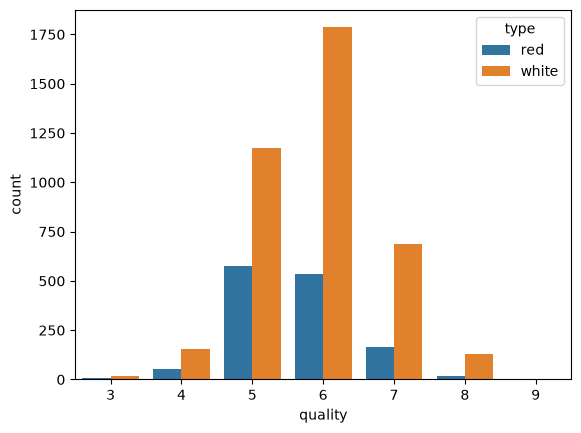

quality
3    0.005642
4    0.038744
5    0.329509
6    0.436336
7    0.160993
8    0.027835
9    0.000940
Name: proportion, dtype: float64


In [4]:
sns.countplot(data=df, x="quality", hue="type")
plt.show()

print(df["quality"].value_counts(normalize=True).sort_index())

### Observações

**1. As notas se concentram em 5 e 6.**
A nota 6 representa cerca de 43% dos vinhos e a nota 5 cerca de 33%:
juntas, somam aproximadamente 3 em cada 4 amostras. A nota 7 tem
cerca de 16%, e as notas 3, 4, 8 e 9 somadas não chegam a 8%.

**2. Apenas as notas de 3 a 9 aparecem.**
Embora a escala vá de 0 a 10, nenhum vinho recebeu notas extremas
(0, 1, 2 ou 10). A nota 9 tem apenas 5 amostras, todas de vinho branco.

**3. Tintos e brancos têm notas um pouco diferentes.**
No vinho tinto, a nota mais comum é 5; no branco, é 6.

**O que isso significa para os modelos:**
- **Regressão:** com tantas amostras perto de 5 e 6, o modelo tende
  a prever valores nessa região e deve errar mais nos vinhos muito
  bons ou muito ruins.
- **Classificação:** prever a nota exata seria inviável para as notas
  raras (5 amostras de nota 9 não bastam para o modelo aprender).
  Isso justifica agrupar as notas em faixas, como pede o enunciado,
  e avaliar técnicas de balanceamento.
- **Divisão treino/teste:** a separação deve ser estratificada pela
  `quality`, para que as notas raras apareçam nos dois conjuntos.

## 4. Distribuição das variáveis (histogramas)

Como há cerca de 3× mais vinhos brancos (3.958) que tintos (1.359), cada
tipo foi normalizado separadamente (`stat="density", common_norm=False`):
assim os histogramas comparam o **formato** das distribuições de tintos e
brancos, e não a quantidade de vinhos de cada tipo. O tamanho de cada grupo
aparece na legenda.

In [ ]:
# Apenas as 11 features; a quality já foi analisada na seção 3
colunas_numericas = df.select_dtypes("number").columns.drop("quality")

# Rótulo da legenda com o tamanho de cada grupo, ex.: "white (n=3958)"
n = df["type"].value_counts()
df_hist = df.assign(tipo=df["type"].map(lambda t: f"{t} (n={n[t]})"))

# Uma grade de 4 linhas x 3 colunas, um gráfico para cada variável
# (11 variáveis: a última posição da grade fica vazia)
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    sns.histplot(data=df_hist, x=coluna, hue="tipo", bins=40, ax=eixo,
                 stat="density", common_norm=False)
    eixo.set_title(coluna)
    # "Density" do seaborn se confundiria com a variável density
    eixo.set_ylabel("Densidade (normalizada por tipo)")

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

### Observações dos histogramas

**1. Vinhos tintos e brancos têm perfis químicos diferentes.**
O `total sulfur dioxide` mostra a maior separação: os tintos ficam
quase todos abaixo de 75, e os brancos se concentram entre 100 e 200.
Os tintos também têm mais `volatile acidity`, `chlorides` e
`sulphates`; os brancos têm mais `residual sugar`.
→ O `type` deve entrar como variável no modelo.

**2. Várias variáveis são assimétricas, com cauda longa à direita.**
`residual sugar`, `chlorides`, `free sulfur dioxide` e `sulphates`
concentram a maioria dos valores à esquerda, com poucos valores muito altos.
→ Modelos lineares podem ser afetados; uma transformação logarítmica
pode ser testada.

**3. As variáveis estão em escalas muito diferentes.**
`density` varia entre 0,99 e 1,04, enquanto `total sulfur dioxide`
vai de 6 a 440.
→ É necessário padronizar os dados antes de modelos sensíveis a
escala, como regressão linear regularizada, KNN e SVM.

**4. Existem valores extremos, mas eles são reais.**
Os eixos se estendem bem além da maioria dos dados (`residual sugar`
até 65,8, `free sulfur dioxide` até 289), por causa de poucas amostras.
Esses valores estão dentro das faixas do artigo original.
→ Serão analisados com boxplots; a princípio, devem ser mantidos.

## 5. Outliers (boxplots)

Os histogramas mostraram caudas longas em várias variáveis. Aqui os boxplots
mostram quantos valores ficam fora do intervalo interquartil (IQR) e se é
o caso de mantê-los ou removê-los.

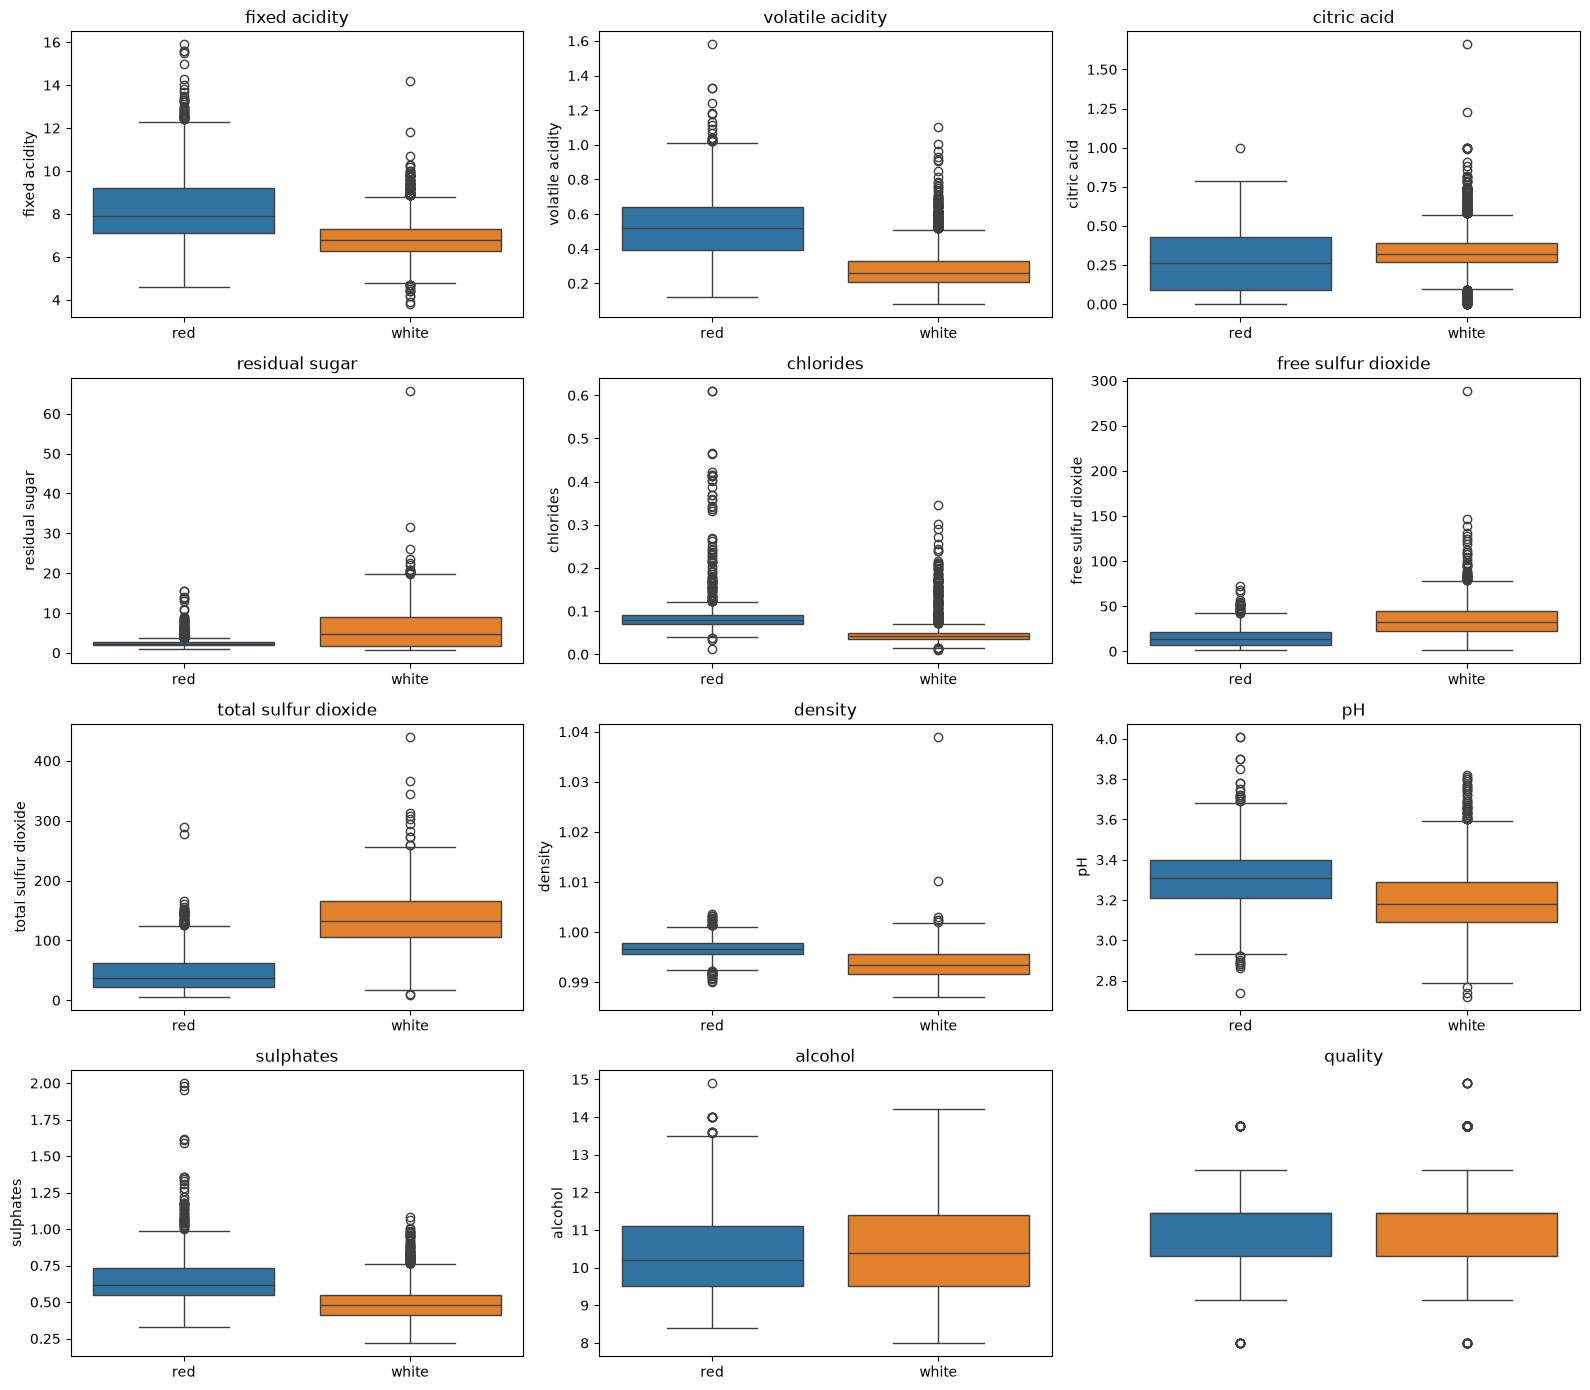

In [9]:
# Mesma grade da seção 4: um boxplot por variável, tintos e brancos lado a lado
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for eixo, coluna in zip(eixos.flatten(), colunas_numericas):
    # hue="type" mantém as mesmas cores dos histogramas
    sns.boxplot(data=df, x="type", y=coluna, hue="type", legend=False, ax=eixo)
    eixo.set_title(coluna)
    eixo.set_xlabel("")

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [10]:
def percentual_outliers(serie):
    """% de valores fora do intervalo [Q1 - 1,5*IQR, Q3 + 1,5*IQR] (critério do boxplot)."""
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    fora = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    return fora.mean() * 100


# Calculado separadamente por tipo, porque tintos e brancos têm distribuições diferentes
outliers = df.groupby("type")[colunas_numericas].agg(percentual_outliers).T.round(1)
outliers.sort_values("white", ascending=False)

type,red,white
citric acid,0.1,5.6
chlorides,6.4,4.7
quality,2.0,3.9
volatile acidity,1.4,3.4
fixed acidity,3.0,2.7
sulphates,4.0,2.5
pH,2.1,1.2
free sulfur dioxide,1.9,1.1
residual sugar,9.3,0.4
total sulfur dioxide,3.3,0.4


### Observações

_TODO_

## 6. Relação das variáveis com a qualidade

Como a `quality` só assume valores inteiros, um scatter plot de feature × quality
formaria faixas horizontais. Por isso são usados boxplots de cada variável por nota.

Os vinhos são separados por `type` porque a proporção de brancos cresce nas notas
altas (67% na nota 5, 89% na nota 8, 100% na nota 9). Sem a separação, uma
tendência poderia refletir apenas a mistura de tipos, e não a qualidade.

As notas 3 (30 vinhos) e 9 (5 vinhos, todos brancos) têm poucas amostras, assim
como a nota 8 entre os tintos: essas caixas são menos confiáveis e devem ser
interpretadas com cautela.

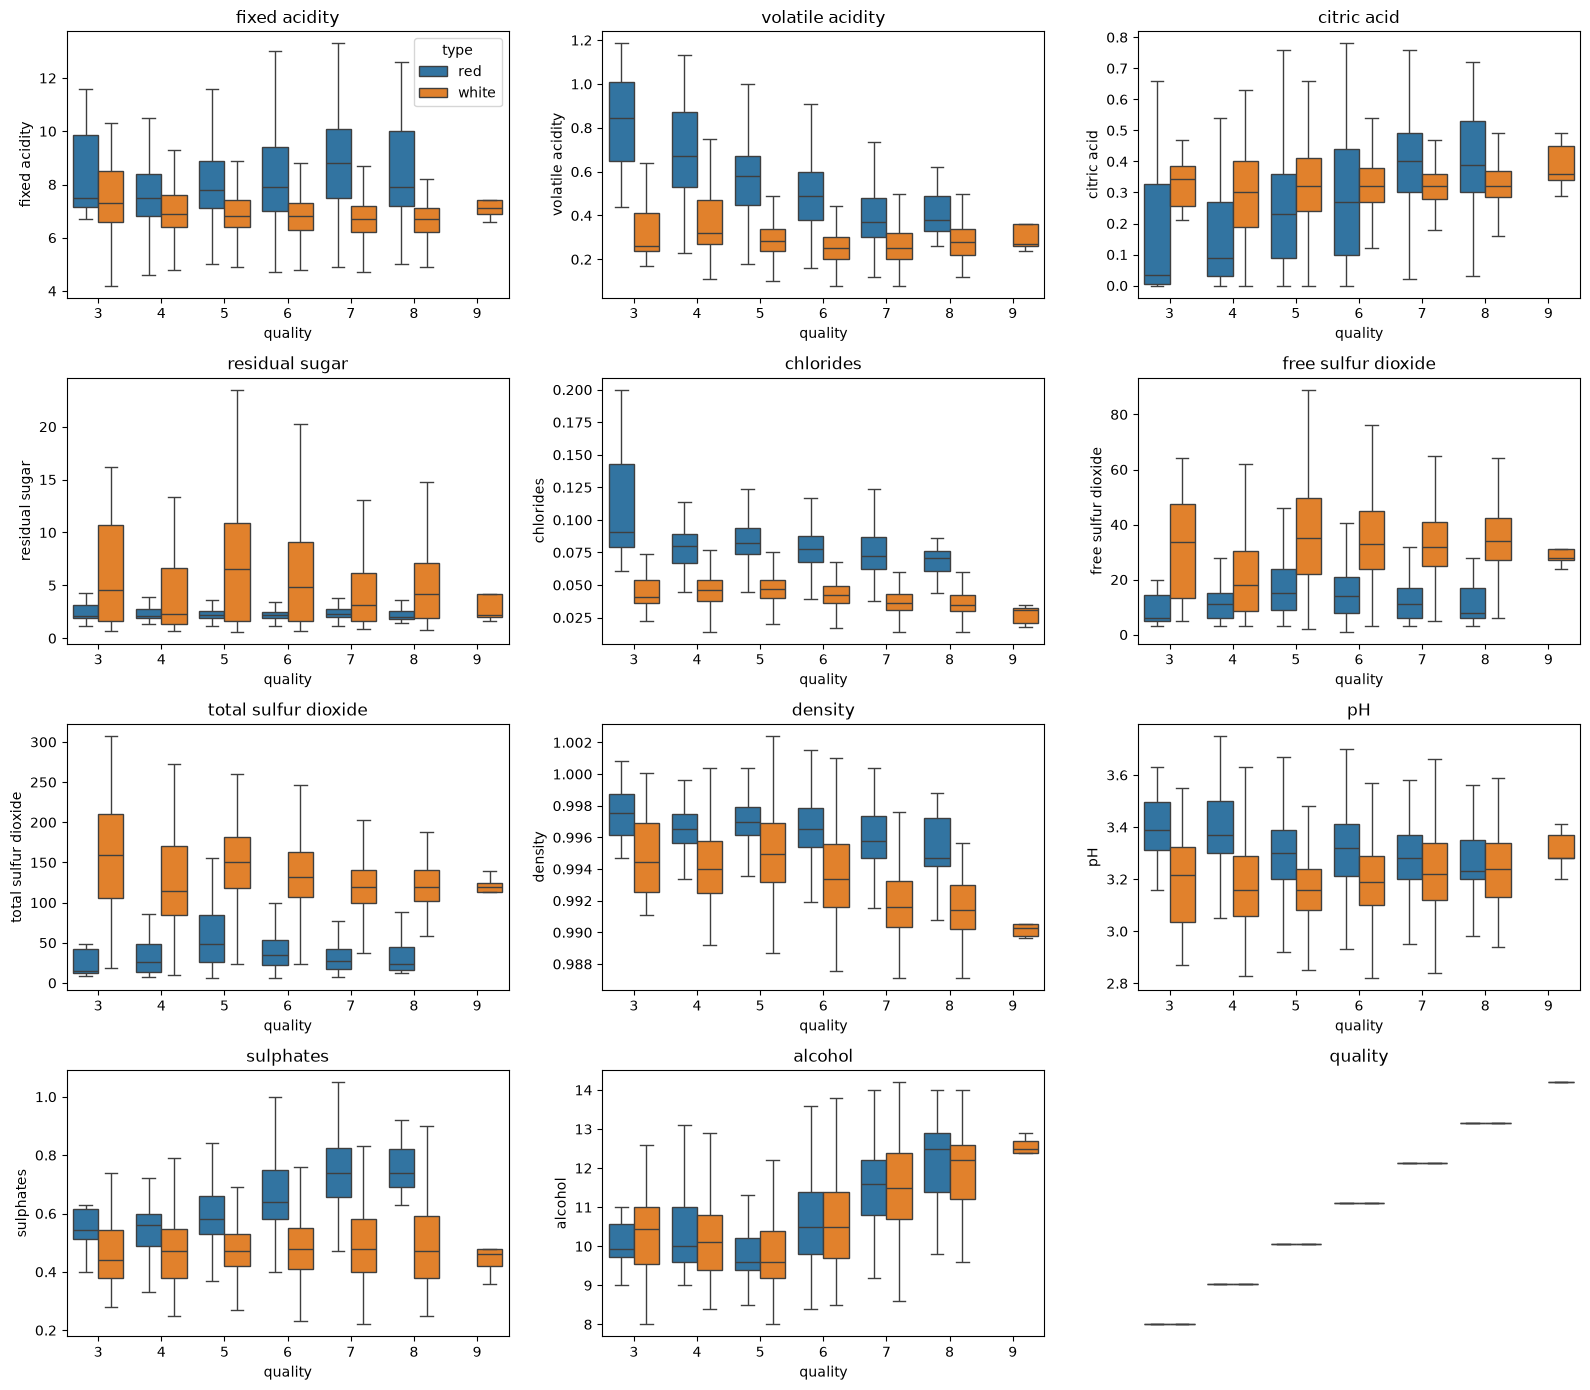

In [13]:
fig, eixos = plt.subplots(4, 3, figsize=(16, 14))

for i, (eixo, coluna) in enumerate(zip(eixos.flatten(), colunas_numericas)):
    # hue="type" separa tintos e brancos em cada nota.
    # showfliers=False esconde os outliers (já analisados na seção 5),
    # para o eixo y não esticar e a tendência entre as notas ficar visível.
    # A legenda aparece só no primeiro gráfico, para não repetir em todos.
    sns.boxplot(data=df, x="quality", y=coluna, hue="type", showfliers=False,
                legend=(i == 0), ax=eixo)
    eixo.set_title(coluna)

eixos.flatten()[-1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Amostras por nota e tipo (o tinto não tem nenhum vinho com nota 9)
print(pd.crosstab(df["type"], df["quality"]))

# Mediana de cada variável por tipo e nota: confirma em números a tendência dos boxplots
df.groupby(["type", "quality"])[colunas_numericas].median().T.round(3)

### Observações

_TODO_

## 7. Relações entre variáveis (scatter plots)

Pares de variáveis com relação física esperada (e correlação alta):
`density` × `alcohol`, `density` × `residual sugar` e
`free sulfur dioxide` × `total sulfur dioxide`.

In [ ]:
# TODO: scatter plots dos pares acima, coloridos por type

### Observações

_TODO_

## 8. Matriz de correlação

Correlação de cada variável com a `quality` e entre as próprias variáveis
(multicolinearidade, que afeta a interpretação dos coeficientes na regressão).

In [ ]:
# TODO: heatmap da matriz de correlação + ranking da correlação com quality

### Observações

_TODO_

## 9. Conclusões e próximos passos

Resumo das decisões para o pré-processamento e a modelagem:

- _TODO_